# SteelCo Ltd: Sales Data Cleaning & Visual Analysis (Q3-Q4 2022)

**Objective:** clean the SteelCo transaction data, rebuild the Excel dashboard KPIs in Python, and extract insights on regions, countries and product groups.

**Data:** `data/SteelCo_Data_Analysis.xlsx`, sheet `Taul1`: one row per product line / country / quarter shipment with *volume (kg)*, *revenue (€)* and *gross margin (€)*.

**Workflow:** data quality checks, then cleaning with an audit trail, then reconciliation against the Excel dashboard, then KPIs and visual analysis, then findings.

The reusable functions live in [`src/steelco_analysis.py`](../src/steelco_analysis.py); this notebook calls them and explains each step.

In [1]:
%matplotlib inline
import warnings; warnings.filterwarnings("ignore")
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import sys; sys.path.insert(0, "../src")   # make src/ importable
import steelco_analysis as sa

pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = 30
DATA_PATH = "../data/SteelCo_Data_Analysis.xlsx"

## 1. Load & inspect the raw data

In [2]:
raw = sa.load_raw(DATA_PATH)
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

4,134 rows x 8 columns


,product_group,steel_grade,region,country,quarter,volume_kg,revenue_eur,gross_margin_eur
0,CORE,Core 304,EMEA,Belgium,Q3 2022,"30,401.00","10,008.25","1,083.80"
1,CORE,Core 304,EMEA,Belgium,Q3 2022,"21,311.00","6,715.07",751.55
2,CORE,Core 304,EMEA,Belgium,Q3 2022,"53,681.50","16,914.99","3,151.70"
3,CORE,Core 304,EMEA,Belgium,Q4 2022,"30,077.80","9,477.48","1,149.35"
4,CORE,Core 304,EMEA,Belgium,Q4 2022,"134,380.50","77,734.46","42,622.26"


In [3]:
raw.info()
print("\nMissing values per column:\n", raw.isna().sum().to_string())
print("\nExact duplicate rows:", raw.duplicated().sum())
print("\nUnique values -> product groups:", raw['product_group'].nunique(),
      "| steel grades:", raw['steel_grade'].nunique(),
      "| regions:", raw['region'].nunique(),
      "| countries:", raw['country'].nunique())
raw.describe()

<class 'pandas.DataFrame'>
RangeIndex: 4134 entries, 0 to 4133
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   product_group     4134 non-null   str    
 1   steel_grade       4134 non-null   str    
 2   region            4134 non-null   str    
 3   country           4134 non-null   str    
 4   quarter           4134 non-null   str    
 5   volume_kg         4134 non-null   float64
 6   revenue_eur       4134 non-null   float64
 7   gross_margin_eur  4134 non-null   float64
dtypes: float64(3), str(5)
memory usage: 258.5 KB

Missing values per column:
 product_group       0
steel_grade         0
region              0
country             0
quarter             0
volume_kg           0
revenue_eur         0
gross_margin_eur    0

Exact duplicate rows: 5

Unique values -> product groups: 5 | steel grades: 21 | regions: 5 | countries: 115


,volume_kg,revenue_eur,gross_margin_eur
count,"4,134.00","4,134.00","4,134.00"
mean,"1,051,117.38","267,393.78","97,705.76"
std,"6,448,511.73","1,047,257.17","400,546.21"
min,"-57,267.00","-84,138.03","-85,498.28"
25%,"6,060.00","8,610.11","2,254.94"
50%,"40,400.00","38,096.22","12,309.38"
75%,"219,382.10","157,710.42","51,590.53"
max,"118,649,285.40","17,667,731.61","7,103,307.90"


## 2. Data quality checks

There are no missing values, but the numeric columns contain values that need a decision: negative volumes, negative revenue / margin, zero-volume rows, a placeholder region, and abbreviated country names.

In [4]:
checks = pd.Series({
    "Negative volume":                    (raw.volume_kg < 0).sum(),
    "Zero volume":                        (raw.volume_kg == 0).sum(),
    "Negative revenue":                   (raw.revenue_eur < 0).sum(),
    "Negative gross margin":              (raw.gross_margin_eur < 0).sum(),
    "Margin larger than revenue":         (raw.gross_margin_eur > raw.revenue_eur).sum(),
    "Region = 'Not assigned'":            (raw.region == "Not assigned").sum(),
    "Exact duplicate rows":               raw.duplicated().sum(),
}, name="rows")
checks.to_frame()

,rows
Negative volume,7
Zero volume,369
Negative revenue,26
Negative gross margin,413
Margin larger than revenue,136
Region = 'Not assigned',1
Exact duplicate rows,5


In [5]:
# Look at the negative-volume rows before deciding what to do with them
raw[raw.volume_kg < 0]

,product_group,steel_grade,region,country,quarter,volume_kg,revenue_eur,gross_margin_eur
601,CORE,Core 321,EMEA,Turkey,Q4 2022,"-22,220.00","-11,599.50","-5,866.21"
2620,DURA,Dura 410,Asia Pacific,Japan,Q4 2022,"-2,020.00","-2,769.21",815.03
3025,DURA,Dura 4024,EMEA,Utd.Arab Emir.,Q4 2022,"-2,550.00","-5,213.75","-4,246.66"
3147,DURA,Dura 4024,EMEA,Netherlands,Q3 2022,"-3,220.87","-5,243.32","-3,427.90"
3573,DURA,Dura 4419Mo,EMEA,Slovakia,Q3 2022,"-1,010.00",-407.55,-136.80
3761,DURA,Dura 4110,Asia Pacific,Vietnam,Q4 2022,"-57,267.00","-84,138.03","-59,861.20"
3980,DURA,Dura 4116,Asia Pacific,Malaysia,Q3 2022,"-18,180.00","-30,728.00","-13,574.56"


## 3. Cleaning (with an audit trail)

| Issue | Decision | Why |
|---|---|---|
| Inconsistent text / abbreviations (`Russian Fed.`, `Utd.Arab Emir.`, `USA`) | Standardise | Readable labels, safe joins with other data |
| `Not assigned` region/country row | **Drop** | Cannot be attributed to any market |
| Negative volume (7 rows) | **Drop** | Physically impossible |
| Negative revenue / margin | **Keep, flag** | Credit notes, returns and genuine losses are part of the P&L |
| Exact duplicate rows | **Keep, flag** | No transaction ID, so identical rows may be separate shipments |
| Zero-volume rows | **Keep** | Price adjustments; excluded only from price-per-kg calculations |

In [6]:
df, audit = sa.clean_data(raw)
display(audit)
print(f"\nRows: {len(raw):,} -> {len(df):,}")
df.head()

,step,rows_affected,rows_remaining,revenue_removed_eur,note
0,Standardise text / country labels,0,4134,0.00,11 country abbreviations mapped to full names
1,Drop 'Not assigned' placeholder row,1,4133,0.00,No region/country; revenue 0 but a €47.5k marg...
2,Drop negative-volume rows,7,4126,"-140,099.36",Volume cannot be negative (returns booked as -kg)
3,Flag exact duplicate rows (kept),0,4126,0.00,5 repeated rows flagged; no transaction ID to ...
4,Flag negative revenue / margin rows (kept),0,4126,0.00,"19 negative-revenue rows, 407 loss-making rows..."



Rows: 4,134 -> 4,126


,product_group,steel_grade,region,country,quarter,volume_kg,revenue_eur,gross_margin_eur,is_possible_duplicate,is_loss_making,has_negative_revenue,margin_pct,price_per_kg
0,CORE,Core 304,EMEA,Belgium,Q3 2022,"30,401.00","10,008.25","1,083.80",False,False,False,0.11,0.33
1,CORE,Core 304,EMEA,Belgium,Q3 2022,"21,311.00","6,715.07",751.55,False,False,False,0.11,0.32
2,CORE,Core 304,EMEA,Belgium,Q3 2022,"53,681.50","16,914.99","3,151.70",False,False,False,0.19,0.32
3,CORE,Core 304,EMEA,Belgium,Q4 2022,"30,077.80","9,477.48","1,149.35",False,False,False,0.12,0.32
4,CORE,Core 304,EMEA,Belgium,Q4 2022,"134,380.50","77,734.46","42,622.26",False,False,False,0.55,0.58


In [7]:
# Save the cleaned dataset for reuse (Power BI / Excel / further modelling)
from pathlib import Path
Path("../outputs").mkdir(exist_ok=True)
df.to_csv("../outputs/steelco_clean.csv", index=False)
audit.to_csv("../outputs/cleaning_audit.csv", index=False)

## 4. Reconciliation with the Excel dashboard

Before trusting any new analysis, check that Python reproduces the numbers from the pivot-table dashboard.

In [8]:
rec = sa.reconcile(raw, df)
display(rec.style.format({"excel_dashboard": "{:,.0f}", "python_raw": "{:,.0f}",
                          "python_clean": "{:,.0f}", "clean_vs_raw_pct": "{:+.4f}%"}))

,excel_dashboard,python_raw,python_clean,clean_vs_raw_pct
revenue_eur,"1,105,400,000","1,105,405,890","1,105,545,989",+0.0127%
volume_kg,"4,345,300,000","4,345,319,269","4,345,425,737",+0.0025%
gross_margin_eur,"403,900,000","403,915,614","403,954,412",+0.0096%


**Result:** Python on the raw data matches the Excel dashboard (revenue €1,105.4M, volume 4,345.3M kg, gross margin €403.9M). The cleaned data differs by less than 0.02%, so the cleaning steps do not change any conclusion. The dashboard figures were produced from the unfiltered sheet, which is worth knowing if the negative-volume rows were meant to be excluded.

## 5. Headline KPIs

In [9]:
t = sa.totals(df)
print(f"Total revenue       : EUR {t.revenue_eur/1e6:,.1f} M")
print(f"Total gross margin  : EUR {t.gross_margin_eur/1e6:,.1f} M  ({t.margin_pct:.1%} of revenue)")
print(f"Total volume        : {t.volume_kg/1e6:,.1f} M kg")
print(f"Avg realised price  : EUR {t.avg_price_eur_per_kg:.3f} per kg")

Total revenue       : EUR 1,105.5 M
Total gross margin  : EUR 404.0 M  (36.5% of revenue)
Total volume        : 4,345.4 M kg
Avg realised price  : EUR 0.254 per kg


In [10]:
fmt = {"volume_kg": "{:,.0f}", "revenue_eur": "{:,.0f}", "gross_margin_eur": "{:,.0f}",
       "margin_pct": "{:.1%}", "revenue_share": "{:.1%}", "volume_share": "{:.1%}", "margin_share": "{:.1%}"}
by_region = sa.summarise(df, "region")
by_region.style.format(fmt)

,volume_kg,revenue_eur,gross_margin_eur,margin_pct,revenue_share,volume_share,margin_share
region,,,,,,,
EMEA,"2,578,698,086","555,938,657","200,825,419",36.1%,50.3%,59.3%,49.7%
North America,"983,348,677","425,080,839","155,640,809",36.6%,38.4%,22.6%,38.5%
Asia Pacific,"79,385,100","69,131,339","21,601,279",31.2%,6.3%,1.8%,5.3%
South America,"703,993,874","55,395,154","25,886,904",46.7%,5.0%,16.2%,6.4%


## 6. Visual analysis
### 6.1 Regions: where the business is

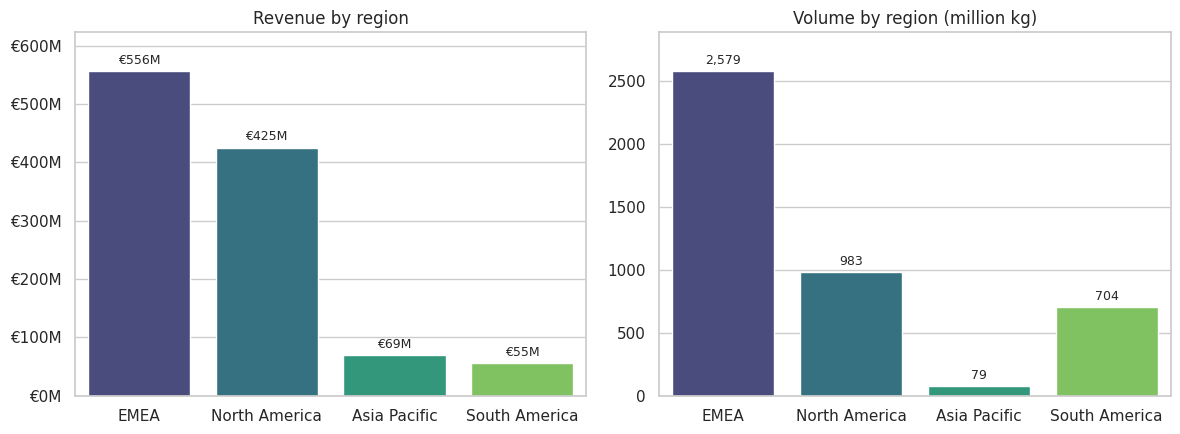

In [11]:
fig = sa.plot_region_revenue_volume(df); plt.show()

EMEA is the largest region on both measures and a much bigger share of volume than of revenue. North America is the second pillar: it earns a similar margin rate to EMEA on far less volume. Asia Pacific is small in this dataset.

### 6.2 Countries: concentration of revenue

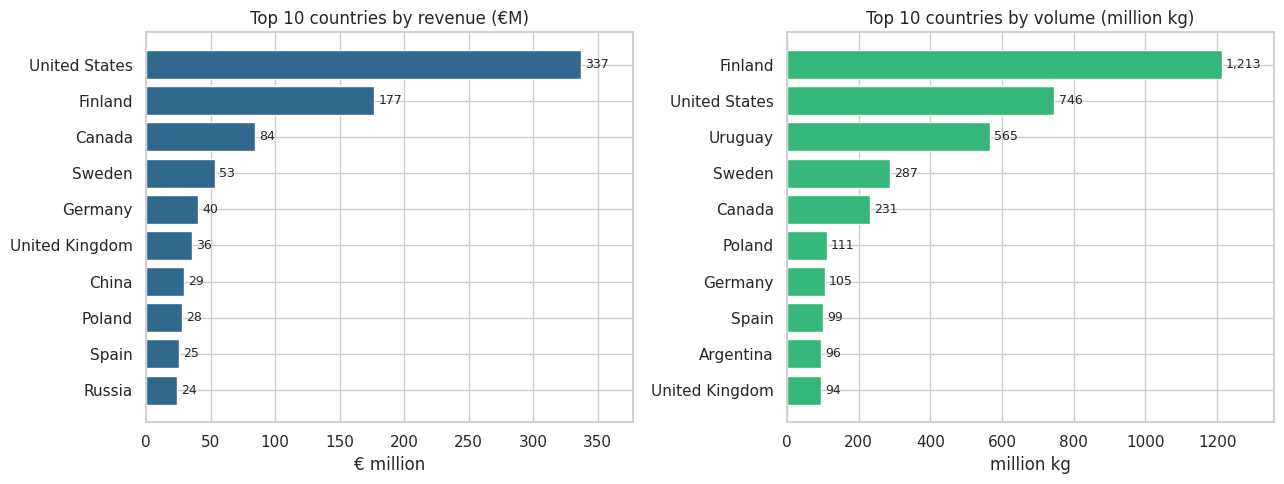

In [12]:
fig = sa.plot_top_countries(df); plt.show()

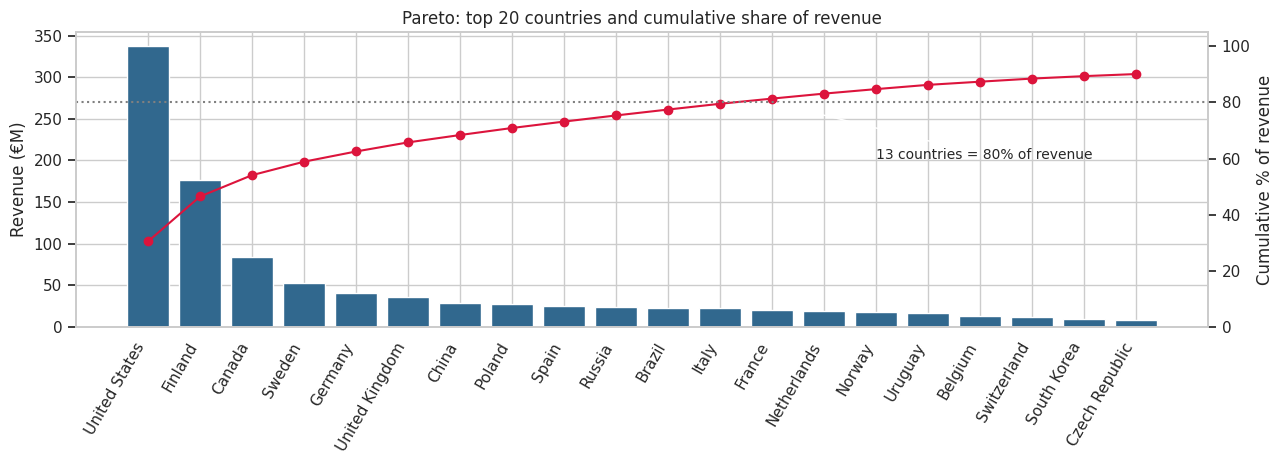

In [13]:
fig = sa.plot_pareto_countries(df); plt.show()

Revenue is highly concentrated. The United States is the biggest revenue market, while Finland is the biggest by volume, which means Finland ships a lot of low-priced material (see 6.5). The Pareto chart shows that a small group of countries delivers 80% of revenue, so account management should focus there.

### 6.3 Product groups: mix and profitability

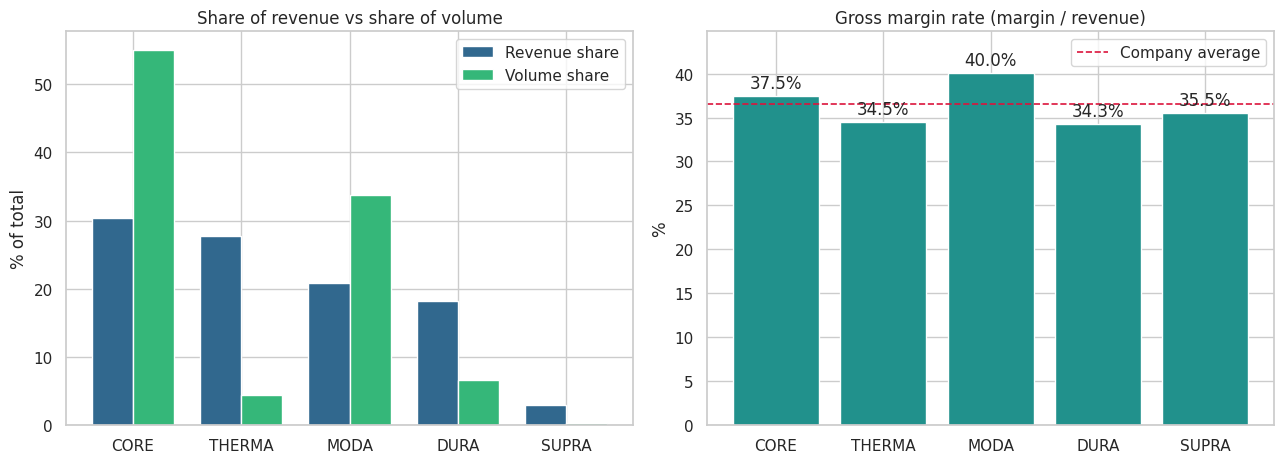

In [14]:
fig = sa.plot_product_mix(df); plt.show()

In [15]:
prod = sa.summarise(df, "product_group").reindex(sa.PRODUCT_ORDER)
prod[["revenue_share", "volume_share", "margin_share", "margin_pct"]].style.format("{:.1%}")

,revenue_share,volume_share,margin_share,margin_pct
product_group,,,,
CORE,30.4%,55.0%,31.1%,37.5%
THERMA,27.7%,4.3%,26.2%,34.5%
MODA,20.8%,33.8%,22.8%,40.0%
DURA,18.2%,6.6%,17.1%,34.3%
SUPRA,2.9%,0.2%,2.8%,35.5%


CORE is volume-heavy (more than half of all kg) but earns only about 30% of revenue. THERMA is the opposite: about 4% of volume but nearly 28% of revenue, i.e. a high-value niche. Margin *rates* are fairly similar across groups (34-40%), and MODA actually has the highest rate.

### 6.4 Region x product heatmap and quarter-on-quarter trend

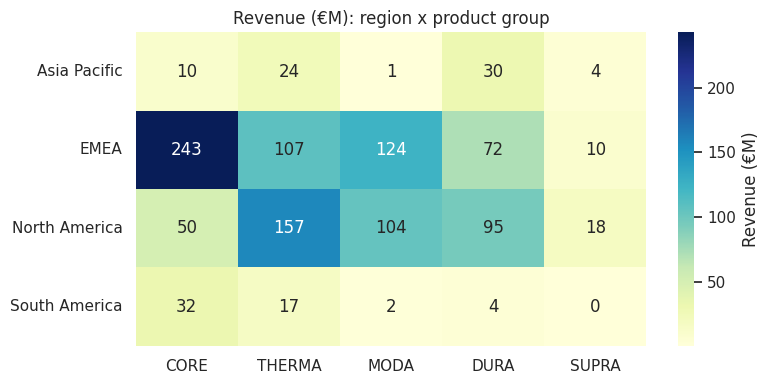

In [16]:
fig = sa.plot_region_product_heatmap(df); plt.show()

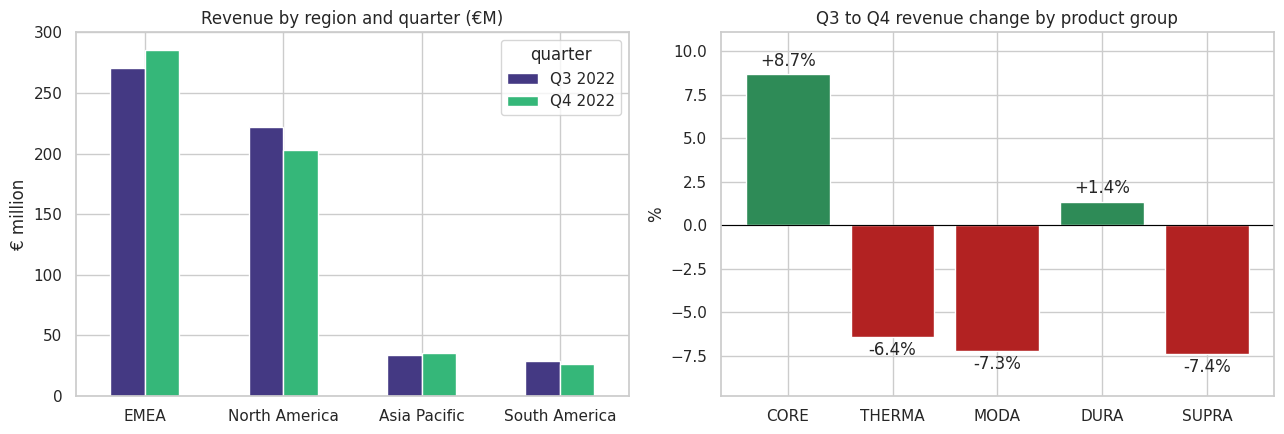

In [17]:
fig = sa.plot_quarter_comparison(df); plt.show()

In [18]:
display(sa.quarter_on_quarter(df, "region").style.format({"Q3 2022": "{:,.0f}", "Q4 2022": "{:,.0f}",
                                                           "change_eur": "{:+,.0f}", "change_pct": "{:+.1%}"}))

quarter,Q3 2022,Q4 2022,change_eur,change_pct
region,,,,
EMEA,"270,209,417","285,729,240","+15,519,823",+5.7%
North America,"222,148,751","202,932,088","-19,216,663",-8.7%
Asia Pacific,"33,843,494","35,287,845","+1,444,352",+4.3%
South America,"28,941,452","26,453,702","-2,487,750",-8.6%


EMEA sells mainly CORE, whereas North America leans on THERMA, so the two regions are exposed to different product risks. Between Q3 and Q4, EMEA and Asia Pacific grew while North America and South America declined, leaving company revenue slightly down (-0.9%). Only two quarters are available, so treat this as a signal, not a trend.

### 6.5 Pricing and margin quality (outliers)

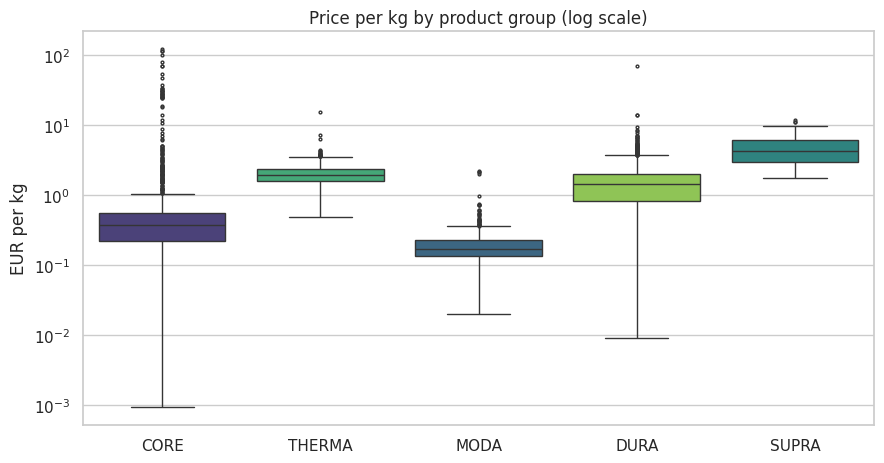

In [19]:
fig = sa.plot_price_per_kg(df); plt.show()

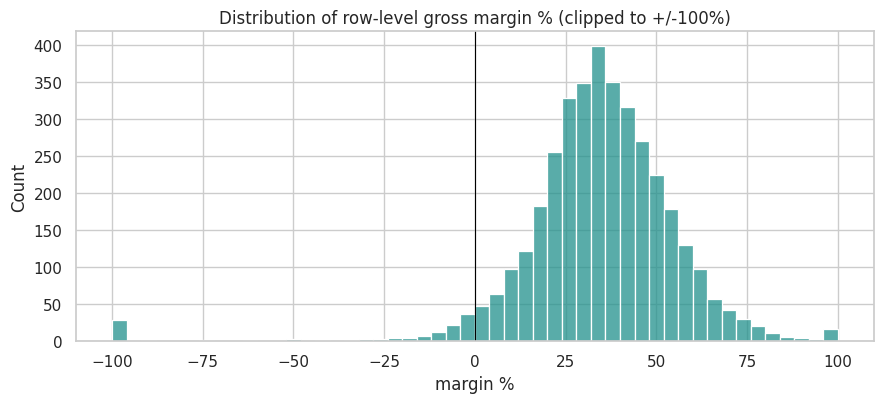

In [20]:
fig = sa.plot_margin_distribution(df); plt.show()

In [21]:
# Which rows sit at extreme price per kg? (possible unit or booking issues worth checking with the business)
low = df[df.price_per_kg < 0.10].groupby(["country", "steel_grade"]).agg(
    rows=("volume_kg", "size"), volume_kg=("volume_kg", "sum"), revenue_eur=("revenue_eur", "sum"))
low.assign(price_per_kg=lambda d: d.revenue_eur / d.volume_kg).sort_values("volume_kg", ascending=False).head(8)

rows      volume_kg   revenue_eur  price_per_kg
country     steel_grade                                                 
Finland     Core 304LN      6 638,796,073.60 42,140,197.58          0.07
Uruguay     Core 304LN      6 525,684,143.50 10,341,521.17          0.02
Argentina   Core 304LN      6  92,034,987.50  2,882,104.20          0.03
Sweden      Core 304       11  42,183,309.35  2,054,318.27          0.05
            Core 301LN      7  33,556,201.38  2,999,974.22          0.09
Italy       Moda 340        6  26,606,934.60  1,749,927.08          0.07
Finland     Core 301LN      2  20,235,616.62  1,810,757.71          0.09
Switzerland Core 301LN      4  18,179,628.32    241,573.56          0.01

Price per kg differs by about two orders of magnitude between product groups (MODA lowest, SUPRA highest), so comparing groups by volume alone is misleading. A few CORE rows (mainly Finland, Core 304LN) have unusually high volume at very low prices, which should be validated with the data owner (unit of measure, by-product or scrap sales) before drawing conclusions about Finland's profitability.

## 7. Key findings & corrections to the dashboard / presentation

The cell below recomputes the numbers from the data so the text cannot drift from the analysis.

In [22]:
reg = sa.summarise(df, "region"); cty = sa.summarise(df, "country"); prod = sa.summarise(df, "product_group")
cum = cty.revenue_eur.cumsum() / cty.revenue_eur.sum()
q = df.groupby("quarter", observed=True).revenue_eur.sum()

print(f"1. EMEA = {reg.loc['EMEA','revenue_share']:.1%} of revenue, {reg.loc['EMEA','volume_share']:.1%} of volume, "
      f"{reg.loc['EMEA','margin_share']:.1%} of gross margin.")
print(f"2. USA = {cty.loc['United States','revenue_share']:.1%} of revenue; Finland = {cty.loc['Finland','volume_share']:.1%} of volume.")
print(f"3. {(cum < 0.8).sum() + 1} of {len(cty)} countries generate 80% of revenue.")
print(f"4. CORE + THERMA = {prod.loc[['CORE','THERMA'],'revenue_share'].sum():.1%} of revenue "
      f"and {prod.loc[['CORE','THERMA'],'volume_share'].sum():.1%} of volume.")
print(f"5. Q3 -> Q4 revenue change: {q.iloc[1]/q.iloc[0]-1:+.1%}.")
print(f"6. {df.is_loss_making.mean():.1%} of rows are loss-making (total EUR {df.loc[df.is_loss_making,'gross_margin_eur'].sum()/1e6:,.2f} M).")

1. EMEA = 50.3% of revenue, 59.3% of volume, 49.7% of gross margin.
2. USA = 30.5% of revenue; Finland = 27.9% of volume.
3. 13 of 114 countries generate 80% of revenue.
4. CORE + THERMA = 58.1% of revenue and 59.4% of volume.
5. Q3 -> Q4 revenue change: -0.9%.
6. 9.9% of rows are loss-making (total EUR -1.29 M).


### Two labelling issues spotted while reconciling

1. **"Margin by Product Group" on the dashboard is a share of total margin, not a margin rate.** CORE's 31.2% is its share of the €403.9M total margin. Its actual gross margin rate (margin / revenue) is about 37.5%. Same for EMEA's 49.7% "gross margin" tile. The table below shows both.
2. **Slide 9 states CORE + THERMA are 87% of volume.** The data gives about 59% (CORE 55% + THERMA 4%). The 87% figure is closer to CORE + MODA.

In [23]:
compare = prod[["margin_share", "margin_pct"]].rename(
    columns={"margin_share": "share of total margin (as on dashboard)", "margin_pct": "gross margin rate (margin / revenue)"})
compare.style.format("{:.1%}")

,share of total margin (as on dashboard),gross margin rate (margin / revenue)
product_group,,
CORE,31.1%,37.5%
THERMA,26.2%,34.5%
MODA,22.8%,40.0%
DURA,17.1%,34.3%
SUPRA,2.8%,35.5%


## 8. Recommendations (data-backed)

* **Protect the core markets:** EMEA and North America deliver ~89% of revenue; the USA and Finland alone deliver ~46%. Prioritise key-account management there.
* **Grow the high-value mix:** THERMA and SUPRA earn far more revenue per kg than CORE/MODA. Shifting even a small share of volume toward them lifts revenue without extra tonnage.
* **Investigate low-price / high-volume rows** (Finland CORE grades) and the loss-making rows before setting targets.
* **Asia Pacific is small today** in this data; the market research suggests it is the largest and still growing steel region, so test expansion with targeted pilots.
* **Fix reporting labels** (margin share vs margin rate) so decision-makers read the right metric.

*Limitations: two quarters of data only; no cost or customer ID columns; no transaction ID to confirm duplicates.*